In [ ]:
### THIS IS A COPY OF FRESH_COOY , ORIGINALLY LOCATED IN CODE_CLEANUP_II
### RUN THIS WITH THE NEW MFIVS

In [1]:
# Further files with the same prefix means progress. This ones has less extra cells. Only what is needed.
import pandas as pd
import numpy as np
from math import sqrt, pi, exp
from arch import arch_model
import yfinance as yf 
from scipy.optimize import minimize
import warnings
from arch.__future__ import reindexing
from arch.utility.exceptions import ConvergenceWarning
# from srcA.msGarch import msGARCH
# from srcA.metrics import metrics
# from srcA.msGarch import msGARCHIV
from tqdm import tqdm

from xgboost import XGBRegressor
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="y is poorly scaled")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [2]:

import os, sys
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
os.chdir("/Users/shah/CODE_BOOK_4/THESIS_WORKING/THESIS_2")
sys.modules.pop("srcB", None)



In [4]:

import sys, os
sys.path.insert(0, "/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/MFIV_calibration")
from srcB.models_MFIV import estimate_naive10_mfiv, estimate_garch_mfiv


In [ ]:
# ### outputs
# # Load NEW from temp_modelling
# import pickle 
# with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_05.pkl", "rb") as f:
#     outputs_by_year = pickle.load(f)
# outputs_by_year[2021]["q1"].columns


Index(['rv', 'rt', 'date_time', 'garch', 'garch_mfiv', 'garch_mfiv_avg',
       'regime_switching_mfiv', 'regime_state', 'selected_horizon', 'MFIV_191',
       'MFIV_382', 'MFIV_573', 'MFIV_764'],
      dtype='str')

In [6]:
# COPIED FROM ANALYSIS
import pickle 
with open("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/outputs_by_year/outputs_by_year_03.pkl", "rb") as f:
    outputs_by_year = pickle.load(f)


#### Market

In [ ]:
# RFR FIXED 11 AUG
 
import pandas as pd
import numpy as np
from scipy.stats import norm
 
 
class Chain:
    def __init__(self):
        self.instruments = []
 
class Instrument:
    def __init__(self, symbol, strike, right, direction, price_per_contract, expiry, option_price_btc):
        self.Symbol = symbol
        self.Strike = strike
        self.Right = right
        self.Direction = direction
        self.Price = price_per_contract
        self.Expiry = expiry
        self.OptionPriceBTC = option_price_btc
 
class Holdings: 
    def __init__(self, cash, now):
        self.time = now
        self.instruments = [] 
        self.cash = cash
        
    def get_cash(self):
        return self.cash
 
    def get_time(self):
        return self.time
        
    def long_instrument(self, instrument):
        self.instruments.append(instrument)
 
    def short_instrument(self, instrument):
        self.instruments.append(instrument)
 
    def close_position(self, key, qty=1):
        # FIX: only remove `qty` matching contracts, not every contract matching the key.
        strike, expiry, right, direction = key
        remaining = []
        removed = 0
        for i in self.instruments:
            if (removed < qty and i.Strike == strike and i.Expiry == expiry
                    and i.Right == right and i.Direction == direction):
                removed += 1
                continue
            remaining.append(i)
        self.instruments = remaining
 
class Market:
    def __init__(self, option_df, time_df, starting_cash=100_000, im_multiplier=0.15, mm_buffer_rate=0.05):
        self.time = time_df.index
        self.option = option_df.copy()
        self.chain = Chain()
        self.option_values = []
        self.time_df = time_df.copy()
        self.spot = None

        # Margin configuration parameters
        self.im_multiplier = im_multiplier    # Standard: 0.10 to 0.15 (10-15%)
        self.mm_buffer_rate = mm_buffer_rate  # Additional market maker buffer standard: 0.05 (5%)
        
        # Live tracking variables
        self.locked_initial_margin = 0.0
        self.locked_buffer_margin = 0.0
                
        self.option["strike"] = self.option["instrument_name"].str.split("-").str[2].astype(float)
        self.option["type"] = self.option["instrument_name"].str.split("-").str[3]
        self.option["maturity"] = pd.to_datetime(
            self.option["instrument_name"].str.split("-").str[1], format="%d%b%y").dt.tz_localize("UTC").dt.floor("h")
        self.option["price_per_contract"] = self.option["price"] * self.option["index_price"]
 
        self.option["date_time"] = pd.to_datetime(self.option["date_time"]).dt.tz_localize("UTC").dt.floor("h")
    
        self.orders = []
        self.transactions = []
        self.starting_cash = starting_cash
        self.cash = starting_cash
        self.equity_history = []
 
        self.now = None
        self.holdings = Holdings(starting_cash, self.now)   
        self.current = pd.DataFrame()

    def calculate_margin_requirements(self):
        # Counts only active short positions to lock margin capital
        short_qty = sum(1 for i in self.holdings.instruments if i.Direction == "sell")
        
        # FIXED: Removed contract_size completely; uses your 100x multiplier scale natively
        self.locked_initial_margin = self.spot * self.im_multiplier * short_qty
        self.locked_buffer_margin = self.spot * self.mm_buffer_rate  * short_qty
        

    def get_total_required_margin(self):
        """Returns the total absolute cash balance that must remain in reserves."""
        return self.locked_initial_margin + self.locked_buffer_margin

    def get_free_liquidity(self):
        """Spendable/usable cash balance remaining after subtracting locked margin reserves."""
        return self.cash - self.get_total_required_margin()

    def update(self, now):
        self.now = pd.Timestamp(now).floor("h")
        self.holdings.time = self.now
        self.current = self.option[self.option["date_time"] == self.now].copy()
        self.spot = self.time_df.loc[self.now, "close"]
        
        # FIXED: Reordered processing sequentially so spot exists before margin math triggers
        self.remove_expired()
        self.calculate_margin_requirements()

        self.chain.instruments = [
            Instrument(
                row["instrument_name"],
                row["strike"],
                row["type"],
                row["direction"],
                row["price_per_contract"],
                row["maturity"],
                row["price"]
            )
            for _, row in self.current.iterrows()
        ]
 
    def remove_expired(self):
        expired_options = [i for i in self.holdings.instruments if i.Expiry <= self.now]
 
        for i in expired_options:
            if i.Right == "C":
                payoff = max(self.spot - i.Strike, 0.0)
            else:
                payoff = max(i.Strike - self.spot, 0.0)
 
            delivery_fee = 0.0
            if payoff > 0:
                base_fee = 0.00015 * self.spot 
                fee_cap = 0.125 * payoff
                delivery_fee = min(base_fee, fee_cap)
                    
            if i.Direction == "buy":
                cash_change = (payoff) - delivery_fee
            else:
                cash_change = -(payoff) - delivery_fee
 
            self.transactions.append({
                "time": self.now,
                "action": "expiry_settlement",
                "symbol": i.Symbol,
                "strike": i.Strike,
                "expiry": i.Expiry,
                "right": i.Right,
                "held_direction": i.Direction,
                "qty": 1,
                "price": payoff,
                "fee": delivery_fee,
                "cash_change": cash_change,
                "cash_before": self.cash,
                "cash_after": self.cash + cash_change,
                "spot": self.spot
            })
 
            self.cash += cash_change
 
        self.holdings.instruments = [i for i in self.holdings.instruments if i.Expiry > self.now]
        self.holdings.cash = self.cash
        self.calculate_margin_requirements()
    
    def buy(self, instrument, qty=1):
        fee = min(0.0003, 0.125 * instrument.OptionPriceBTC) * self.spot * qty
        cash_change = -(instrument.Price * qty + fee)

        if self.get_free_liquidity() + cash_change < 0:
            return None
        # if self.cash + cash_change < 0:
        #     return None

        order = {
            "time": self.now,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "spot_entry": self.spot,
            "side": "long",
            "qty": qty,
            "entry_price": instrument.Price
        }
        self.orders.append(order)

        self.transactions.append({
            "time": self.now,
            "action": "buy_to_open",
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": "buy",
            "qty": qty,
            "price": instrument.Price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.cash = self.cash

        for _ in range(qty):
            self.holdings.instruments.append(
                Instrument(
                    instrument.Symbol,
                    instrument.Strike,
                    instrument.Right,
                    "buy",
                    instrument.Price,
                    instrument.Expiry,
                    instrument.OptionPriceBTC
                )
            )

        self.calculate_margin_requirements()
        return order
        
    def sell(self, instrument, qty=1):
        fee = min(0.0003, 0.125 * instrument.OptionPriceBTC) * self.spot * qty
        cash_change = instrument.Price * qty - fee

        new_initial_margin = self.spot * self.im_multiplier * qty
        new_buffer_margin = self.spot * self.mm_buffer_rate * qty

        if (self.cash + cash_change - self.locked_initial_margin - self.locked_buffer_margin - new_initial_margin - new_buffer_margin < 0):
            return None
        
        order = {
            "time": self.now,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "spot_entry": self.spot,
            "side": "short",
            "qty": qty,
            "entry_price": instrument.Price
        }
        self.orders.append(order)

        self.transactions.append({
            "time": self.now,
            "action": "sell_to_open",
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": "sell",
            "qty": qty,
            "price": instrument.Price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.cash = self.cash

        for _ in range(qty):
            self.holdings.instruments.append(
                Instrument(
                    instrument.Symbol,
                    instrument.Strike,
                    instrument.Right,
                    "sell",
                    instrument.Price,
                    instrument.Expiry,
                    instrument.OptionPriceBTC
                )
            )

        self.calculate_margin_requirements()
        return order
     
    # def liquidate(self, key, instrument, qty=1):
    #     if instrument.Direction == "buy":
    #         action_name = "sell_to_close"
    #         exec_dir = "sell"
    #     else:
    #         action_name = "buy_to_close"
    #         exec_dir = "buy"
 
    #     current_inst = next((i for i in self.chain.instruments if i.Symbol == instrument.Symbol), None)
    #     current_price = current_inst.Price if current_inst else instrument.Price
    #     opt_price_btc = current_inst.OptionPriceBTC if current_inst else instrument.OptionPriceBTC
 
    #     fee = min(0.0003, 0.125 * opt_price_btc) * self.spot * qty
        
    #     if exec_dir == "sell":
    #         cash_change = (current_price * qty) - fee
    #     else:
    #         cash_change = -(current_price * qty + fee)
 
    #     self.transactions.append({
    #         "time": self.now,
    #         "action": action_name,
    #         "symbol": instrument.Symbol,
    #         "strike": instrument.Strike,
    #         "expiry": instrument.Expiry,
    #         "right": instrument.Right,
    #         "held_direction": instrument.Direction,
    #         "qty": qty,
    #         "price": current_price,
    #         "fee": fee,
    #         "cash_change": cash_change,
    #         "cash_before": self.cash,
    #         "cash_after": self.cash + cash_change,
    #         "spot": self.spot
    #     })
 
    #     self.cash += cash_change
    #     self.holdings.close_position(key, qty)
    #     self.holdings.cash = self.cash
    #     self.calculate_margin_requirements()
    def liquidate(self, key, instrument, qty=1):
        if instrument.Direction == "buy":
            action_name = "sell_to_close"
            exec_dir = "sell"
        else:
            action_name = "buy_to_close"
            exec_dir = "buy"

        opposite_direction = "sell" if instrument.Direction == "buy" else "buy"

        current_inst = next(
            (
                i for i in self.chain.instruments
                if (
                    i.Strike == instrument.Strike
                    and i.Expiry == instrument.Expiry
                    and i.Right == instrument.Right
                    and i.Direction == opposite_direction
                )
            ),
            None
        )

        if current_inst is None:
            return None

        current_price = current_inst.Price
        opt_price_btc = current_inst.OptionPriceBTC

        fee = min(
            0.0003,
            0.125 * opt_price_btc
        ) * self.spot * qty

        if exec_dir == "sell":
            cash_change = current_price * qty - fee
        else:
            cash_change = -(current_price * qty + fee)

        self.transactions.append({
            "time": self.now,
            "action": action_name,
            "symbol": instrument.Symbol,
            "strike": instrument.Strike,
            "expiry": instrument.Expiry,
            "right": instrument.Right,
            "held_direction": instrument.Direction,
            "qty": qty,
            "price": current_price,
            "fee": fee,
            "cash_change": cash_change,
            "cash_before": self.cash,
            "cash_after": self.cash + cash_change,
            "spot": self.spot
        })

        self.cash += cash_change
        self.holdings.close_position(key, qty)
        self.holdings.cash = self.cash
        self.calculate_margin_requirements()

        return True
                
    def get_equity_history(self):
        if not self.equity_history:
            return pd.DataFrame(columns=[
                "option_value",
                "cash",
                "equity",
                "required_margin",
                "free_liquidity"
            ])

        return pd.DataFrame(self.equity_history).set_index("time")
    
    def record_equity(self):
        option_value = self.option_value()
        self.option_values.append(option_value)

        self.equity_history.append({
            "time": self.now,
            "option_value": option_value,
            "cash": self.cash,
            "equity": self.cash + option_value,
            "required_margin": self.get_total_required_margin(),
            "free_liquidity": self.get_free_liquidity()
        })
 
    def get_order(self):
        return self.orders
 
    def in_position(self):
        return len(self.holdings.instruments) > 0   
 
    def close_price(self, n=60):
        return self.time_df["close"].loc[:self.now].tail(n)
 
    def variance(self, n=60):
        close = self.close_price(n)
        ret = np.log(close / close.shift(1)).dropna()
        if len(ret) == 0:
            return np.nan
        return ret.var() * (365 * 24)
 
    def std(self, n=60):
        close = self.close_price(n)
        ret = np.log(close / close.shift(1)).dropna()
        if len(ret) == 0:
            return np.nan
        return ret.std()
 
    def option_value(self):
        option_value = 0.0
 
        if self.now is None or not self.holdings.instruments:
            return 0.0
        spot = self.close_price(n=1).iloc[-1]
        var = self.variance(n=60)
        r = float(self.time_df.loc[self.now, "rfr"])
 
        if pd.isna(var) or var <= 0 or pd.isna(spot):
            return 0.0
 
        for instrument in self.holdings.instruments:
            strike = instrument.Strike
            tau = (instrument.Expiry - self.now) / pd.Timedelta(days=365)
 
            if tau <= 0:
                if instrument.Right == "C":
                    price_now = max(spot - strike, 0.0)
                else:
                    price_now = max(strike - spot, 0.0)
            else:
                den = np.sqrt(var) * np.sqrt(tau)
                if den <= 0:
                    price_now = 0.0
                else:
                    d1 = (np.log(spot / strike) + (r + var / 2) * tau) / den
                    d2 = d1 - den
                    Nd1 = norm.cdf(d1)
                    Nd2 = norm.cdf(d2)
                    Nd1_put = norm.cdf(-d1)
                    Nd2_put = norm.cdf(-d2)
 
                    if instrument.Right == "C":
                        price_now = spot * Nd1 - strike * np.exp(-r * tau) * Nd2
                    else:
                        price_now = strike * np.exp(-r * tau) * Nd2_put - spot * Nd1_put
 
            if instrument.Direction == "sell":
                option_value -= price_now
            else:
                option_value += price_now
 
        return option_value
 
    def pricer(self, key):
        strike, expiry, right, direction = key
 
        if self.now is None:
            return 0.0
 
        spot = self.close_price(n=1).iloc[-1]
        var = self.variance(n=60)
        # r = 0.01
        r = float(self.time_df.loc[self.now, "rfr"])
 
        if pd.isna(var) or var <= 0 or pd.isna(spot):
            return 0.0
 
        instrument = next(
            (i for i in self.holdings.instruments
            if i.Strike == strike and i.Expiry == expiry and i.Right == right and
            i.Direction == direction),
            None
        )
 
        if instrument is None:
            return 0.0
 
        tau = (instrument.Expiry - self.now) / pd.Timedelta(days=365)
 
        if tau <= 0:
            if instrument.Right == "C":
                price_now = max(spot - strike, 0.0)
            else:
                price_now = max(strike - spot, 0.0)
        else:
            den = np.sqrt(var) * np.sqrt(tau)
            if den <= 0:
                price_now = 0.0
            else:
                d1 = (np.log(spot / strike) + (r + var / 2) * tau) / den
                d2 = d1 - den
                Nd1 = norm.cdf(d1)
                Nd2 = norm.cdf(d2)
                Nd1_put = norm.cdf(-d1)
                Nd2_put = norm.cdf(-d2)
 
                if instrument.Right == "C":
                    price_now = spot * Nd1 - strike * np.exp(-r * tau) * Nd2
                else:
                    price_now = strike * np.exp(-r * tau) * Nd2_put - spot * Nd1_put
 
        if instrument.Direction == "sell":
            return -price_now
        else:
            return price_now 

            

#### testing_funct

### TRADING LOGIC
For garch family models : signal is the relative spread between a forecast and trailing rv.
For regime_switching_mfiv : signal is the spread between MFIV horizon H and rv over that same horizon.
Entry Logic : fires long when signal is in the top decile of its own rolling distribution. (s_now ≥ q_hi). opposite for short
So when forecast is unusually far below realized, it goes short vol(strangle).
That is "trade the direction the model expects variance to move" strategy. buy vol expansion, sell vol contraction.
Rather than the classic "sell rick implied vol, dont care about direction"


In [ ]:
# NEW TESTING 07
def testing_execute_trading_strategy( bt_year, bt_quarter, model, outputs_by_year, market, quantity = 10, lookback_hours = 60, mean_hours = 60, hold_days = 7, expiry_days = 30, ql = 0.1, qh = 0.9, z = 1.645):
    out_full = outputs_by_year[bt_year][bt_quarter].copy()
    out_full.index = pd.to_datetime(out_full.index,utc=True).floor("h")

    out_full = out_full.loc[~out_full.index.duplicated(keep="first")]

    now_list = out_full.index
    snapshots = []
    greek_tests = []

    MFIV_HORIZONS = [191, 382, 573, 764]

    # VALID_MODELS = [ "garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]
    VALID_MODELS = [ "garch", "garch_mfiv", "garch_n_mfiv", "garch_mfiv_avg", "regime_switching_mfiv"]

    if model not in VALID_MODELS:
        raise ValueError(f"model must be one of {VALID_MODELS}")

    rv = out_full["rv"].astype(float)

    use_dynamic_hold = model == "garch_n_mfiv"
    use_dynamic_mfiv_signal = ( model == "regime_switching_mfiv" )

    if model == "garch":
        garch_series = out_full["garch"].astype(float)

    elif model == "garch_mfiv":
        garch_series = out_full["garch_mfiv"].astype(float)

    elif model == "garch_n_mfiv":
        garch_series = out_full["garch"].astype(float)

    elif model == "garch_mfiv_avg":
        garch_series = out_full["garch_mfiv_avg"].astype(float)

    else:
        garch_series = None

    regime_state = pd.to_numeric(out_full["regime_state"], errors="coerce")

    selected_horizon_series = out_full["selected_horizon"].astype("string")

# when do we use this mfiv signal . 
    if use_dynamic_mfiv_signal:
        signal = pd.Series(np.nan, index=out_full.index, dtype=float)

        rolling_forecast_mean = pd.Series(np.nan, index=out_full.index, dtype=float)

        q_lo_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        q_hi_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        forecast_top10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        forecast_bot10_series = pd.Series(np.nan, index=out_full.index, dtype=float)

        for H in MFIV_HORIZONS:
            col = f"MFIV_{H}"

            mfiv_h = out_full[col].astype(float)

            # Cumulative realised variance known before time t:
            # rv[t-H] + ... + rv[t-1]
            trailing_rv_h = (rv.rolling(window=H, min_periods=H).sum().shift(1))

            signal_h = (mfiv_h - trailing_rv_h) / trailing_rv_h

            forecast_mean_h = mfiv_h.rolling(window=H, min_periods=H).mean()

            q_lo_h = signal_h.rolling( window=H, min_periods=H).quantile(ql)

            q_hi_h = signal_h.rolling(window=H, min_periods=H).quantile(qh) # 90th quantile for instance of the signal

            forecast_top10_h = (forecast_mean_h.rolling(window=H,min_periods=H).quantile(qh))

            forecast_bot10_h = (forecast_mean_h.rolling(window=H, min_periods=H).quantile(ql))

            mask = (selected_horizon_series == col)

            signal.loc[mask] = signal_h.loc[mask]

            rolling_forecast_mean.loc[mask] = forecast_mean_h.loc[mask]

            q_lo_series.loc[mask] = q_lo_h.loc[mask]

            q_hi_series.loc[mask] = q_hi_h.loc[mask]

            forecast_top10_series.loc[mask] = forecast_top10_h.loc[mask]

            forecast_bot10_series.loc[mask] = forecast_bot10_h.loc[mask]

    else:
        signal = (garch_series - rv) / rv

        q_lo_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql)

        q_hi_series = signal.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh)

        rolling_forecast_mean = (garch_series.rolling(window=mean_hours, min_periods=mean_hours).mean())

        forecast_top10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(qh))

        forecast_bot10_series = (rolling_forecast_mean.rolling(window=lookback_hours, min_periods=lookback_hours).quantile(ql))

    entered_day = None
    position_side = None
    entry_time = None
    position_hold_hours = None

    entry_selected_horizon = None
    entry_mfiv = None
    entry_lower_boundary = None
    entry_upper_boundary = None

    def reset_position_state():
        nonlocal entered_day
        nonlocal position_side
        nonlocal entry_time
        nonlocal position_hold_hours
        nonlocal entry_selected_horizon
        nonlocal entry_mfiv
        nonlocal entry_lower_boundary
        nonlocal entry_upper_boundary

        entered_day = None
        position_side = None
        entry_time = None
        position_hold_hours = None

        entry_selected_horizon = None
        entry_mfiv = None
        entry_lower_boundary = None
        entry_upper_boundary = None

    def liquidate_all():
        for instrument in list( market.holdings.instruments):
            key = ( instrument.Strike, instrument.Expiry, instrument.Right, instrument.Direction)
            market.liquidate( key, instrument )

    def save_snapshot(now):
        snapshots.append({
            "time": now,
            "model": model,
            "cash": market.cash,
            "equity": (market.cash + market.option_value()),
            "option_value": market.option_value(),
            "entry_selected_horizon": (entry_selected_horizon),
            "entry_mfiv": entry_mfiv,
            "entry_lower_boundary": (entry_lower_boundary),
            "entry_upper_boundary": (entry_upper_boundary),
            "positions": [
                {
                    "symbol": instrument.Symbol,
                    "strike": instrument.Strike,
                    "expiry": instrument.Expiry,
                    "right": instrument.Right,
                    "direction": instrument.Direction,
                    "entry_price": instrument.Price
                }
                for instrument
                in market.holdings.instruments
            ],
            "orders": list(market.orders)
        })

    for idx, now in enumerate(now_list):
        market.update(now)

        if market.get_free_liquidity() < 0:
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue

        if ( not use_dynamic_mfiv_signal and idx < lookback_hours):
            market.record_equity()
            save_snapshot(now)
            continue

        s_now = signal.iloc[idx]
        q_lo = q_lo_series.iloc[idx]
        q_hi = q_hi_series.iloc[idx]

        forecast_mean_now = (rolling_forecast_mean.iloc[idx])

        forecast_top10 = (forecast_top10_series.iloc[idx])

        forecast_bot10 = (forecast_bot10_series.iloc[idx])

        if (
            pd.isna(s_now)
            or pd.isna(q_lo)
            or pd.isna(q_hi)
            or pd.isna(forecast_mean_now)
            or pd.isna(forecast_top10)
            or pd.isna(forecast_bot10)
        ):
            market.record_equity()
            save_snapshot(now)
            continue

        hour = now.hour

        holdings = list(market.holdings.instruments)

        short_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "sell" )]

        short_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "sell" )]

        long_calls_held = [instrument for instrument in holdings if ( instrument.Right == "C" and instrument.Direction == "buy")]

        long_puts_held = [instrument for instrument in holdings if ( instrument.Right == "P" and instrument.Direction == "buy" )]

        call_count = len(short_calls_held)
        put_count = len(short_puts_held)

        short_position = ( call_count > 0 or put_count > 0)

        long_position = ( len(long_calls_held) > 0 or len(long_puts_held) > 0 )

        has_position = ( short_position or long_position)

        complete_position = (
            (
                call_count > 0
                and put_count > 0
            )
            or (
                len(long_calls_held) > 0
                and len(long_puts_held) > 0
            )
        )

        active_position_side = position_side

        if active_position_side is None:
            if short_position and not long_position:
                active_position_side = "short_strangle"
            elif long_position and not short_position:
                active_position_side = "long_straddle"

        # ---------------------------------------------------------
        # INCOMPLETE POSITION EDGE CASE
        # ---------------------------------------------------------
        if (
            has_position
            and not complete_position
        ):
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue

        # ---------------------------------------------------------
        # EXIT
        # ---------------------------------------------------------
        if has_position:
            should_exit = False

            if (
                entry_time is not None
                and position_hold_hours is not None
                and now >= entry_time + pd.Timedelta(hours=position_hold_hours)
            ):
                should_exit = True

            if (entered_day is not None and now.date() > entered_day):
                if ( active_position_side == "long_straddle" and forecast_mean_now >= forecast_top10 ):
                    should_exit = True

                elif ( active_position_side == "short_strangle" and forecast_mean_now <= forecast_bot10 ):
                    should_exit = True

            if any( instrument.Expiry - now <= pd.Timedelta(hours=12) for instrument in holdings ):
                should_exit = True

            if should_exit:
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

        if complete_position:
            market.record_equity()
            save_snapshot(now)
            continue

        long_entry_signal = ( s_now >= q_hi and 11 <= hour < 15 ) # CHANGED_040826 untested, testing temp first

        short_entry_signal = ( s_now <= q_lo and 11 <= hour < 15 )

        # ––––––––––––––––––––––––––––––––––––––––––
        # TESTING 
        # ––––––––––––––––––––––––––––––––––––––––––
        if not ( long_entry_signal or short_entry_signal):
            market.record_equity()
            save_snapshot(now)
            continue

        last_five = market.close_price(n=5)

        if last_five.empty:
            market.record_equity()
            save_snapshot(now)
            continue

        last = float( last_five.iloc[-1] )

        # ---------------------------------------------------------
        # LONG STRADDLE ENTRY
        # ---------------------------------------------------------
        if long_entry_signal:
            calls = [instrument for instrument in market.chain.instruments
                if (
                    instrument.Right == "C"
                    and instrument.Direction == "buy"
                )
            ]

            puts = [instrument for instrument in market.chain.instruments
                if (
                    instrument.Right == "P"
                    and instrument.Direction == "buy"
                )
            ]

            valid_calls = [instrument for instrument in calls
                if (
                    pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta( days=expiry_days)
                )
            ]

            valid_puts = [instrument for instrument in puts
                if (
                    pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta(days=expiry_days)
                )
            ]

            if not valid_calls or not valid_puts:
                market.record_equity()
                save_snapshot(now)
                continue

            common_expiries = sorted(
                {
                    instrument.Expiry
                    for instrument in valid_calls
                }
                & {
                    instrument.Expiry
                    for instrument in valid_puts
                }
            )

            if not common_expiries:
                market.record_equity()
                save_snapshot(now)
                continue

            expiry = common_expiries[0]

            expiry_calls = [instrument for instrument in valid_calls if instrument.Expiry == expiry ]

            expiry_puts = [ instrument for instrument in valid_puts if instrument.Expiry == expiry ]

            common_strikes = sorted(
                {
                    instrument.Strike
                    for instrument in expiry_calls
                }
                & {
                    instrument.Strike
                    for instrument in expiry_puts
                }
            )

            if not common_strikes:
                market.record_equity()
                save_snapshot(now)
                continue

            atm_strike = min( common_strikes, key=lambda strike: abs(strike - last) )

            long_call = next(
                (
                    instrument for instrument in expiry_calls if instrument.Strike == atm_strike
                ),
                None
            )

            long_put = next(
                (
                    instrument for instrument in expiry_puts if instrument.Strike == atm_strike
                ),
                None
            )

            if ( long_call is None or long_put is None):
                market.record_equity()
                save_snapshot(now)
                continue

            before_count = len(market.holdings.instruments)

            market.buy( long_call, qty=1 )

            market.buy( long_put, qty=1 )

            after_count = len( market.holdings.instruments )

            if ( after_count - before_count == 2):
                entered_day = now.date()
                position_side = ("long_straddle")
                entry_time = now
                position_hold_hours = (hold_days * 24)

            else:
                liquidate_all()
                reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue


        # ---------------------------------------------------------
        # STRIKE HORIZON
        # ---------------------------------------------------------
        if model in ["garch", "garch_mfiv_avg"]:
            strike_horizon = None
            mfiv_now = None

            lower_boundary = last * 0.98
            upper_boundary = last * 1.02

        else:
            if entry_selected_horizon is not None:
                strike_horizon = entry_selected_horizon

            elif model in ["regime_switching_mfiv", "garch_n_mfiv"]:
                selected_col = selected_horizon_series.iloc[idx]

                if pd.isna(selected_col):
                    market.record_equity()
                    save_snapshot(now)
                    continue

                selected_col = str(selected_col)

                try:
                    strike_horizon = int(selected_col.split("_")[1])
                except (
                    IndexError,
                    TypeError,
                    ValueError
                ):
                    market.record_equity()
                    save_snapshot(now)
                    continue

                if strike_horizon not in MFIV_HORIZONS:
                    market.record_equity()
                    save_snapshot(now)
                    continue

            else:
                strike_horizon = 191

            mfiv_col = f"MFIV_{strike_horizon}"

            if mfiv_col not in out_full.columns:
                market.record_equity()
                save_snapshot(now)
                continue

            mfiv_now = float(out_full[mfiv_col].iloc[idx])

            if not np.isfinite(mfiv_now) or mfiv_now <= 0:
                market.record_equity()
                save_snapshot(now)
                continue

            lower_boundary = (
                last
                * np.exp(
                    -z * np.sqrt(mfiv_now)
                )
            )

            upper_boundary = (
                last
                * np.exp(
                    z * np.sqrt(mfiv_now)
                )
            )

        acceptable_calls = [
            instrument
            for instrument
            in market.chain.instruments
            if (
                instrument.Right == "C"
                and instrument.Direction == "sell"
                and instrument.Strike
                >= upper_boundary
                and pd.Timedelta(days=1)
                <= instrument.Expiry - now
                <= pd.Timedelta(
                    days=expiry_days
                )
            )
        ]

        acceptable_puts = [
            instrument
            for instrument
            in market.chain.instruments
            if (
                instrument.Right == "P" and instrument.Direction == "sell" and 
                instrument.Strike <= lower_boundary and 
                pd.Timedelta(days=1) <= instrument.Expiry - now <= pd.Timedelta(days=expiry_days)
            )
        ]
        # ---------------------------------------------------------
        # STRICT TWO-LEG RANGE FILL
        # ---------------------------------------------------------
        selected_calls = []
        selected_puts = []

        common_expiries = sorted(
            {
                instrument.Expiry
                for instrument in acceptable_calls
            }
            & {
                instrument.Expiry
                for instrument in acceptable_puts
            },
            key= lambda expiry_value: abs((expiry_value - now) - pd.Timedelta(days=expiry_days))
        )

        # Prefer one common expiry for both legs.
        for expiry in common_expiries:
            expiry_calls = sorted(
                [
                    instrument
                    for instrument in acceptable_calls
                    if instrument.Expiry == expiry
                ],
                key= lambda instrument: instrument.Strike
            )

            expiry_puts = sorted(
                [
                    instrument
                    for instrument in acceptable_puts
                    if instrument.Expiry == expiry
                ],
                key=lambda instrument: instrument.Strike,
                reverse=True
            )

            if expiry_calls and expiry_puts:
                selected_calls = expiry_calls[:quantity]
                selected_puts = expiry_puts[:quantity]
                break

        # Fallback: allow different expiries only when
        # no common-expiry range exists.
        if not selected_calls or not selected_puts:
            if acceptable_calls:
                call_expiry = min(
                    {
                        instrument.Expiry
                        for instrument in acceptable_calls
                    },
                    key=lambda expiry_value: abs(
                        (expiry_value - now)
                        - pd.Timedelta(days=expiry_days)
                    )
                )

                selected_calls = sorted(
                    [
                        instrument
                        for instrument in acceptable_calls
                        if instrument.Expiry == call_expiry
                    ],
                    key=lambda instrument: instrument.Strike
                )[:quantity]

            if acceptable_puts:
                put_expiry = min(
                    {
                        instrument.Expiry
                        for instrument in acceptable_puts
                    },
                    key=lambda expiry_value: abs( (expiry_value - now) - pd.Timedelta(days=expiry_days))
                )

                selected_puts = sorted(
                    [
                        instrument
                        for instrument in acceptable_puts
                        if instrument.Expiry == put_expiry
                    ],
                    key=lambda instrument: instrument.Strike,
                    reverse=True
                )[:quantity]

        # CHANGED_050826
        # Enforce the same number of call and put legs.
        pair_count = min(len(selected_calls), len(selected_puts), quantity)

        if pair_count == 0:
            market.record_equity()
            save_snapshot(now)
            continue

        selected_calls = selected_calls[:pair_count]
        selected_puts = selected_puts[:pair_count]
        # –––––––––––––––––––––––––––––––––––
        # TESTING
        # –––––––––––––––––––––––––––––––––––
        greek_tests.append({
            "time": now,
            "signal": s_now,
            "q_lo": q_lo
        })
        greek_tests[-1]["selected_calls"] = selected_calls
        greek_tests[-1]["selected_puts"] = selected_puts
        greek_tests[-1]["call_ivs"] = [
            float( market.current.loc[
                (market.current["instrument_name"] == instrument.Symbol)
                & (market.current["direction"] == instrument.Direction),
                "iv"
            ].iloc[0]
        ) for instrument in selected_calls
        ]

        greek_tests[-1]["put_ivs"] = [
            float( market.current.loc[
                (market.current["instrument_name"] == instrument.Symbol)
                & (market.current["direction"] == instrument.Direction),
                "iv"
            ].iloc[0]
        ) for instrument in selected_puts
        ]
        greek_tests[-1]["spot"] = float(market.spot)
        greek_tests[-1]["rfr"] = float(market.time_df.loc[now, "rfr"])
        
        greek_tests[-1]["call_greeks"] = []
        for instrument, iv in zip(selected_calls, greek_tests[-1]["call_ivs"]):
            d1, d2 = get_d1_d2(now, market.spot, instrument.Strike, greek_tests[-1]["rfr"], iv, instrument.Expiry)
            greek_tests[-1]["call_greeks"].append({
                "delta" : get_delta(d1, instrument.Right, instrument.Direction),
                "gamma" : get_gamma( d1, instrument.Right, now, market.spot, iv, instrument.Expiry, instrument.Direction)
            })
        
        greek_tests[-1]["put_greeks"] = []
        for instrument, iv in zip(selected_puts, greek_tests[-1]["put_ivs"]):
            d1, d2 = get_d1_d2(now, market.spot, instrument.Strike, greek_tests[-1]["rfr"], iv, instrument.Expiry)
            greek_tests[-1]["put_greeks"].append({
                "delta" : get_delta(d1, instrument.Right, instrument.Direction),
                "gamma" : get_gamma( d1, instrument.Right, now, market.spot, iv, instrument.Expiry, instrument.Direction)
            })

        # –––––––––––––––––––––––––––––––––––
        
        
        before_call_count = call_count
        before_put_count = put_count

        # Fill calls from closest above the upper boundary outward.
        for instrument in selected_calls:
            market.sell(instrument, qty=1)

        # Fill puts from closest below the lower boundary outward.
        for instrument in selected_puts:
            market.sell(instrument, qty=1)

        holdings_after = list(market.holdings.instruments)

        call_count_after = sum(
            1
            for instrument in holdings_after
            if (
                instrument.Right == "C"
                and instrument.Direction == "sell"
            )
        )

        put_count_after = sum(
            1
            for instrument in holdings_after
            if (
                instrument.Right == "P"
                and instrument.Direction == "sell"
            )
        )

        calls_added = (call_count_after - before_call_count)

        puts_added = (put_count_after - before_put_count)

        # Strict two-leg control:
        # both sides must receive at least one fill.
        if calls_added <= 0 or puts_added <= 0 or calls_added!= puts_added:
            liquidate_all()
            reset_position_state()

            market.record_equity()
            save_snapshot(now)
            continue
        entered_day = now.date()
        position_side = "short_strangle"
        entry_time = now

        if use_dynamic_hold:
            selected_col = (selected_horizon_series.iloc[idx])

            if pd.isna(selected_col):
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            selected_col = str(selected_col)

            try:
                selected_H = int(selected_col.split("_")[1])
            except (
                IndexError,
                TypeError,
                ValueError
            ):
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            if selected_H not in MFIV_HORIZONS:
                liquidate_all()
                reset_position_state()

                market.record_equity()
                save_snapshot(now)
                continue

            position_hold_hours = selected_H

        else:
            position_hold_hours = (hold_days * 24)

        entry_selected_horizon = (strike_horizon)

        entry_mfiv = mfiv_now

        entry_lower_boundary = (lower_boundary)

        entry_upper_boundary = (upper_boundary)

        market.record_equity()
        save_snapshot(now)

    liquidate_all()
    market.record_equity()
    save_snapshot(market.now)
    for test in greek_tests:
        test["entry_equity"] = next(
            s["equity"] for s in snapshots
            if s["time"] == test["time"]
        )
    return snapshots, greek_tests

In [ ]:

### trade prep 
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/rawData")
YEARS = [2019, 2020, 2021]

d_btc_raw_by_year = {}
df_raw_by_year = {}

for y in YEARS:
    d_btc_raw_by_year[y] = pd.read_parquet(DATA_DIR / f"btc_underlying_minutely_{y}.parquet")
    df_raw_by_year[y]    = pd.read_parquet(DATA_DIR / f"derivative_data_{y}.parquet")
for y in YEARS:
    d_btc_raw_by_year[y] = d_btc_raw_by_year[y].set_index(pd.to_datetime(d_btc_raw_by_year[y]["date_time"]))
    df_raw_by_year[y] = df_raw_by_year[y].set_index(pd.to_datetime(df_raw_by_year[y]["date_time"]))


,rv,rt,date_time,garch,garch_mfiv,garch_mfiv_avg,regime_switching_mfiv,regime_state,selected_horizon,MFIV_191,MFIV_382,MFIV_573,MFIV_764
date_time,,,,,,,,,,,,,
2021-04-08 12:00:00+00:00,3.147573e-05,-0.005610,2021-04-08 12:00:00+00:00,0.000008,2.083696e-06,2.107748e-06,0.245961,3.0,MFIV_764,0.000357,0.000881,0.001366,0.001871
2021-04-08 13:00:00+00:00,2.916295e-04,0.017077,2021-04-08 13:00:00+00:00,0.000012,1.862498e-05,1.655347e-05,0.313568,3.0,MFIV_764,0.000332,0.001103,0.001731,0.002385
2021-04-08 14:00:00+00:00,3.090098e-06,0.001758,2021-04-08 14:00:00+00:00,0.000192,9.583076e-06,9.583076e-06,0.424466,3.0,MFIV_764,0.000595,0.001370,0.002295,0.003229
2021-04-08 15:00:00+00:00,2.591615e-05,0.005091,2021-04-08 15:00:00+00:00,0.000057,5.855773e-06,7.580710e-06,0.497467,3.0,MFIV_764,0.000674,0.001523,0.002463,0.003784
2021-04-08 16:00:00+00:00,2.184915e-06,0.001478,2021-04-08 16:00:00+00:00,0.000055,1.214826e-05,7.713858e-06,0.454327,3.0,MFIV_764,0.000585,0.001357,0.002078,0.003456
2021-04-08 17:00:00+00:00,5.821790e-06,-0.002413,2021-04-08 17:00:00+00:00,0.000046,2.264016e-06,2.264016e-06,0.262585,3.0,MFIV_764,0.000369,0.000929,0.001494,0.001997
2021-04-08 18:00:00+00:00,2.240466e-06,0.001497,2021-04-08 18:00:00+00:00,0.000042,2.109553e-06,2.109553e-06,0.293789,3.0,MFIV_764,0.000334,0.000891,0.001425,0.002235
2021-04-08 19:00:00+00:00,9.076913e-06,0.003013,2021-04-08 19:00:00+00:00,0.000037,1.607556e-05,1.444871e-05,0.355832,3.0,MFIV_764,0.000536,0.001205,0.001813,0.002707
2021-04-08 20:00:00+00:00,1.385319e-05,-0.003722,2021-04-08 20:00:00+00:00,0.000035,2.807107e-05,2.451091e-05,0.211281,3.0,MFIV_764,0.000259,0.000799,0.001202,0.001607


In [28]:
### CHECK SPARSE SELECTED_HORIZON.
for y in outputs_by_year:
    for q in outputs_by_year[y]:
        selected_horizon = outputs_by_year[y][q]["selected_horizon"]

        n_nans = selected_horizon.isna().sum()
        total = len(selected_horizon)

        print(
            y,
            q,
            f"NaNs: {n_nans}/{total}",
            f"({n_nans / total:.2%})"
        )


2019 q1 NaNs: 1527/2160 (70.69%)
2019 q2 NaNs: 0/2184 (0.00%)
2019 q3 NaNs: 0/2208 (0.00%)
2019 q4 NaNs: 0/2208 (0.00%)
2020 q1 NaNs: 1527/2184 (69.92%)
2020 q2 NaNs: 0/2184 (0.00%)
2020 q3 NaNs: 0/2208 (0.00%)
2020 q4 NaNs: 0/2208 (0.00%)
2021 q1 NaNs: 1527/2160 (70.69%)
2021 q2 NaNs: 0/2184 (0.00%)
2021 q3 NaNs: 0/2208 (0.00%)
2021 q4 NaNs: 0/2208 (0.00%)


What does each column represent?
- MFIV_H columns at this point represent the cumulative variance over the next H hours in percentage squared variance. so 4056 would mean volatility = sqrt(4056) = 63.7%
- above is old
- current scaling is annualized decimal squared variance


In [29]:
### converts annualized decimal-squared variance into cumulative decimal variance over the next H hours
MFIV_HORIZONS = [191, 382, 573, 764]
QUARTERS = ["q1", "q2", "q3", "q4"]
for y in YEARS:
    for q in QUARTERS:
        out_full = outputs_by_year[y][q].copy()

        for H in MFIV_HORIZONS:
            col = f"MFIV_{H}"

            out_full[col] = ( out_full[col].astype(float) * H / (8760.0) )

        outputs_by_year[y][q] = out_full


In [58]:
outputs_by_year[2021]["q1"]

,rv,rt,date_time,garch,garch_mfiv,garch_mfiv_avg,regime_switching_mfiv,regime_state,selected_horizon,MFIV_191,MFIV_382,MFIV_573,MFIV_764
date_time,,,,,,,,,,,,,
2021-01-01 00:00:00+00:00,1.161073e-05,-0.003407,2021-01-01 00:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.153796,0.733854,0.478925,0.360025
2021-01-01 01:00:00+00:00,1.454392e-06,0.001206,2021-01-01 01:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.554808,0.779203,0.724385,0.555784
2021-01-01 02:00:00+00:00,2.782889e-04,0.016682,2021-01-01 02:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,5.890202,3.014652,2.246171,1.734436
2021-01-01 03:00:00+00:00,6.549349e-05,-0.008093,2021-01-01 03:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,1.220249,0.741221,0.551315,0.415044
2021-01-01 04:00:00+00:00,1.173290e-05,0.003425,2021-01-01 04:00:00+00:00,NaN,NaN,NaN,NaN,NaN,NaN,0.863206,0.532184,0.473839,0.353038
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-03-31 19:00:00+00:00,4.932710e-06,0.002221,2021-03-31 19:00:00+00:00,0.000034,0.000014,0.000017,0.579865,3.0,MFIV_764,1.442320,0.800295,0.717488,0.579865
2021-03-31 20:00:00+00:00,2.861346e-04,-0.016916,2021-03-31 20:00:00+00:00,0.000030,0.000013,0.000020,0.578752,3.0,MFIV_764,1.464171,0.724556,0.757672,0.578752
2021-03-31 21:00:00+00:00,1.207885e-04,0.010990,2021-03-31 21:00:00+00:00,0.000101,0.000013,0.000012,0.860935,3.0,MFIV_764,2.552161,1.315137,1.106751,0.860935


#### HELPERS

In [37]:
import math
import pandas as pd

def norm_pdf(x):
    return math.exp(-x**2 / 2) / math.sqrt(2 * math.pi)

def norm_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


def get_d1_d2(now, spot, strike, rfr, sigma, expiry):
    tau = (expiry - now) / pd.Timedelta(days=365)
    d1_num = math.log(spot / strike) + (rfr + 0.5 * sigma * sigma) * tau
    d1_den = sigma * math.sqrt(tau)
    d1 = d1_num / d1_den
    d2 = d1 - d1_den
    return d1, d2

def get_delta(d1, right, direction):
    delta = norm_cdf(d1)
    if right == "P":
        delta = delta - 1
    if direction == "sell":
        delta *= -1
    return delta

def get_gamma(d1, right, now, spot, sigma, expiry, direction):
    tau = (expiry - now) / pd.Timedelta(days=365)
    gamma = norm_pdf(d1) / (spot * sigma * math.sqrt(tau))
    if direction == "sell":
        gamma *= -1
    return gamma

#### BORROW COLUMN RFR

In [20]:
import pickle
with open ("/Users/shah/CODE_BOOK_4/code_document/REPOSITORIES/data/IS/ready_data/d_btc_by_year.pkl", "rb") as f :
    d_btc_by_year = pickle.load(f)


In [33]:
d_btc_raw_by_year[2021]["rfr"] = d_btc_by_year[2021]["rfr"].reindex(d_btc_raw_by_year[2021].index, method="ffill")

In [35]:
d_btc_raw_by_year[2021]["rfr"]

date_time
2020-12-31 23:00:00+00:00    0.050024
2020-12-31 23:01:00+00:00    0.050024
2020-12-31 23:02:00+00:00    0.050024
2020-12-31 23:03:00+00:00    0.050024
2020-12-31 23:04:00+00:00    0.050024
                               ...   
2022-01-01 22:55:00+00:00    0.119005
2022-01-01 22:56:00+00:00    0.119005
2022-01-01 22:57:00+00:00    0.119005
2022-01-01 22:58:00+00:00    0.119005
2022-01-01 22:59:00+00:00    0.119005
Name: rfr, Length: 527040, dtype: float64

#### TEST

In [39]:
YEAR = 2021
MODEL = "garch_n_mfiv" 

market = Market(
    option_df=df_raw_by_year[YEAR],
    time_df=d_btc_raw_by_year[YEAR],
    starting_cash=100_000,
    im_multiplier=0.15,
    mm_buffer_rate=0.05,
)

greek_tests_2021 = []

for q in ["q1", "q2", "q3", "q4"]:
    snapshots, greek_tests = testing_execute_trading_strategy(
        bt_year=YEAR,
        bt_quarter=q,
        model=MODEL,
        outputs_by_year=outputs_by_year,
        market=market,
        quantity=10,
        expiry_days=30,
        hold_days=7,
        lookback_hours=60,
        mean_hours=60,
        ql=0.1,
        qh=0.90,
        z=1.645
    )

    greek_tests_2021.extend(greek_tests)

In [55]:
print(pd.Series([x["action"] for x in market.transactions]).value_counts())

sell_to_open         139
buy_to_close         101
expiry_settlement     41
buy_to_open           36
sell_to_close         33
Name: count, dtype: int64


In [56]:
greek_tests_2021[0].keys()

dict_keys(['time', 'signal', 'q_lo', 'selected_calls', 'selected_puts', 'call_ivs', 'put_ivs', 'spot', 'rfr', 'call_greeks', 'put_greeks', 'entry_equity'])

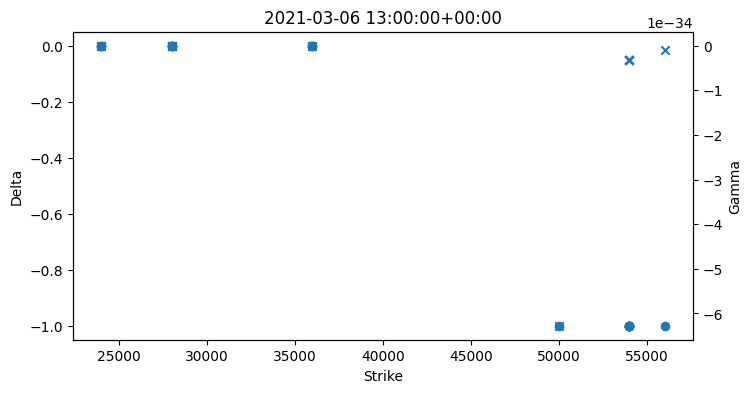

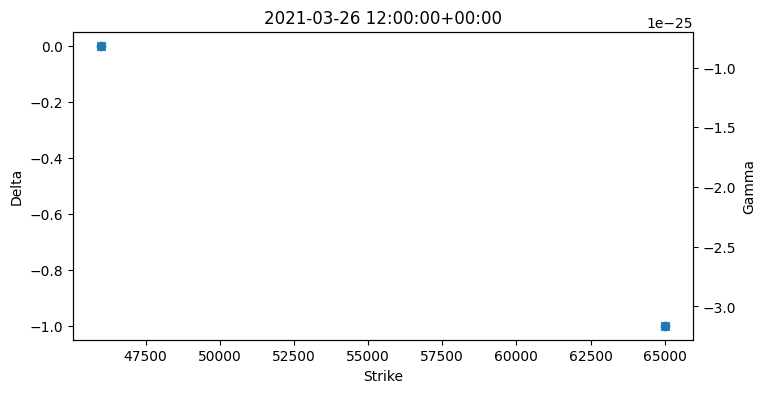

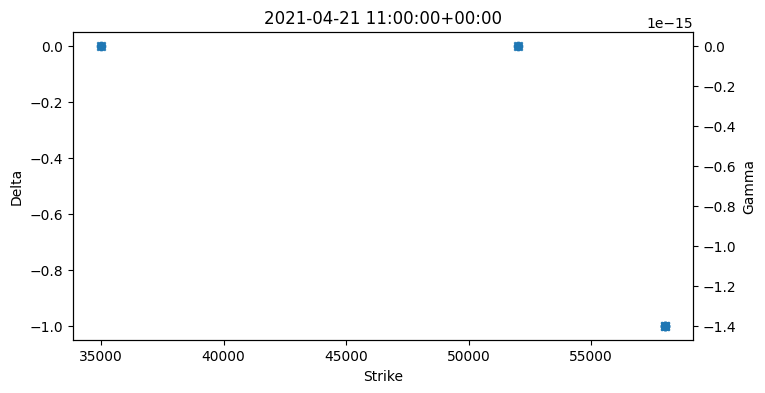

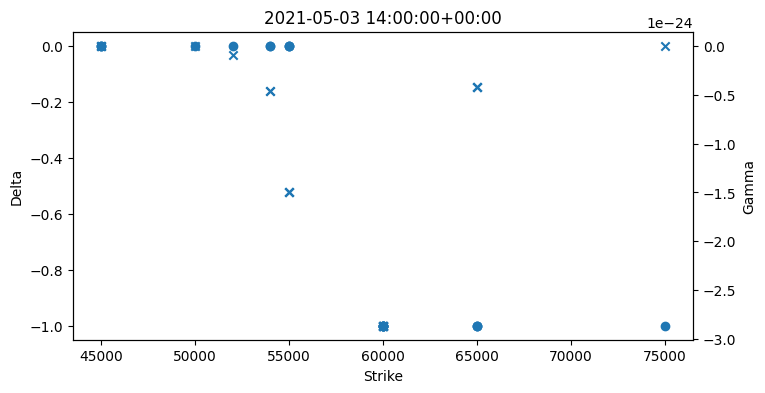

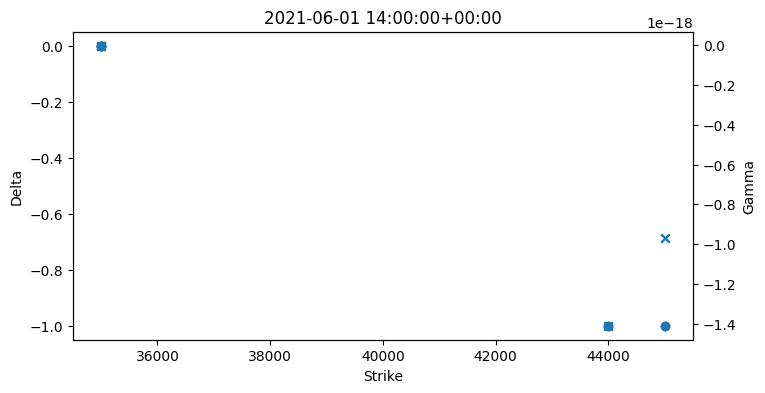

In [57]:
import matplotlib.pyplot as plt

N = 5

for x in greek_tests_2021[:N]:

    strikes = [i.Strike for i in x["selected_calls"] + x["selected_puts"]]
    greeks = x["call_greeks"] + x["put_greeks"]

    delta = [g["delta"] for g in greeks]
    gamma = [g["gamma"] for g in greeks]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(strikes, delta, label="Delta")

    ax2 = ax.twinx()
    ax2.scatter(strikes, gamma, marker="x", label="Gamma")

    ax.set_title(str(x["time"]))
    ax.set_xlabel("Strike")
    ax.set_ylabel("Delta")
    ax2.set_ylabel("Gamma")

    plt.show()

In [ ]:
# what do I want to check really.
# How can these greeks time 